Модель: линейная квантильная регрессия (квантиль 0.9)
Исходные данные:
Часов: 2928
Площадок: 5
Базовая мощность: 6.0 кВт
Резерв: 6.0 кВт

Первоначальная проверка:
Июнь MAE: 0.8219
Июль MAE: 0.8673
Июнь Pinball Loss (q=0.9): 0.1820
Июль Pinball Loss (q=0.9): 0.1949

Кривая обучения:
 train_days  train_mae  validation_mae
          7     1.2401          1.2230
         14     1.0140          0.9751
         21     0.9570          0.9497
         29     0.8219          0.8673


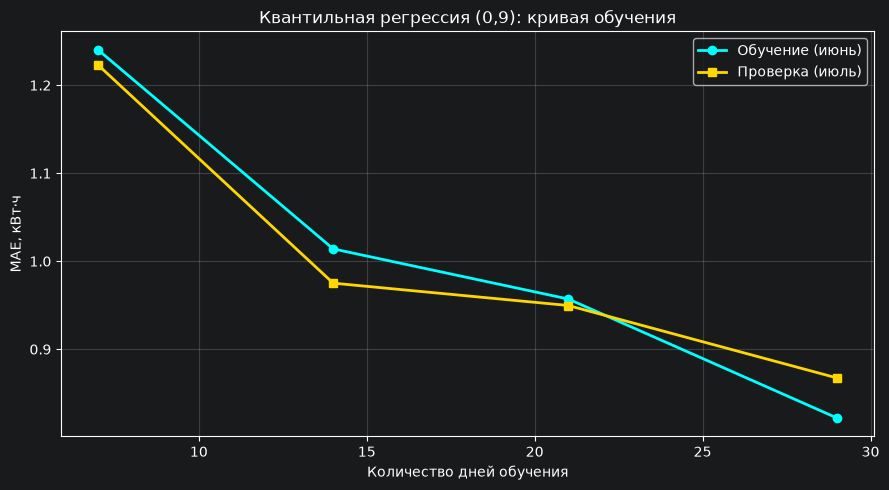


Качество прогнозов за август и сентябрь:
Сценарий A: MAE = 1.0345 кВт·ч; Pinball Loss = 0.1990
Сценарий B: MAE = 1.1972 кВт·ч; Pinball Loss = 0.1965

Качество прогнозов по месяцам:
2023-08, сценарий A: MAE = 1.0177 кВт·ч; Pinball Loss = 0.2356
2023-08, сценарий B: MAE = 1.1058 кВт·ч; Pinball Loss = 0.2220
2023-09, сценарий A: MAE = 1.0518 кВт·ч; Pinball Loss = 0.1611
2023-09, сценарий B: MAE = 1.2915 кВт·ч; Pinball Loss = 0.1701


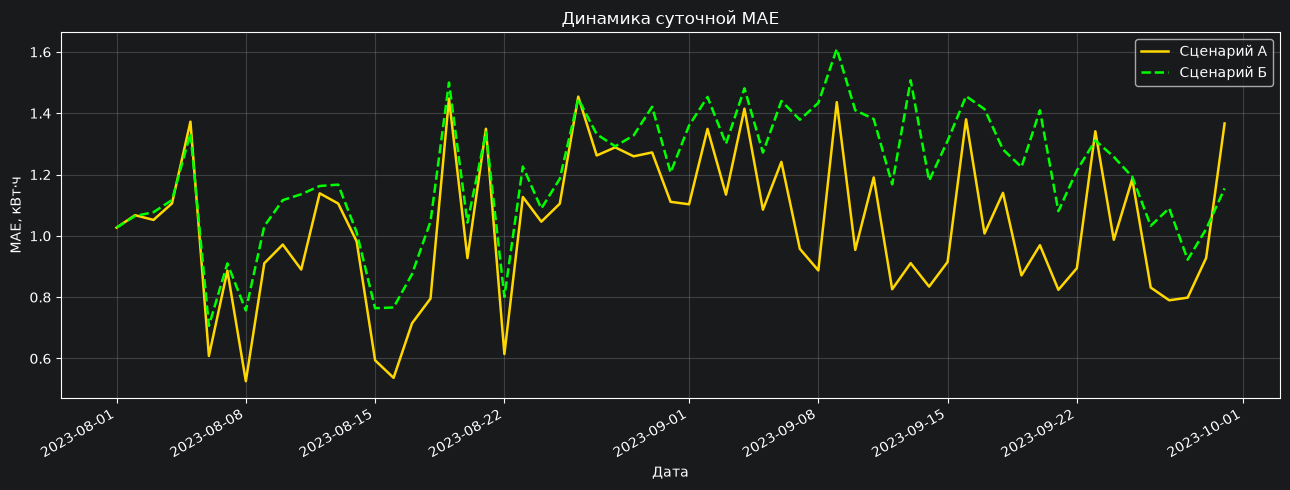

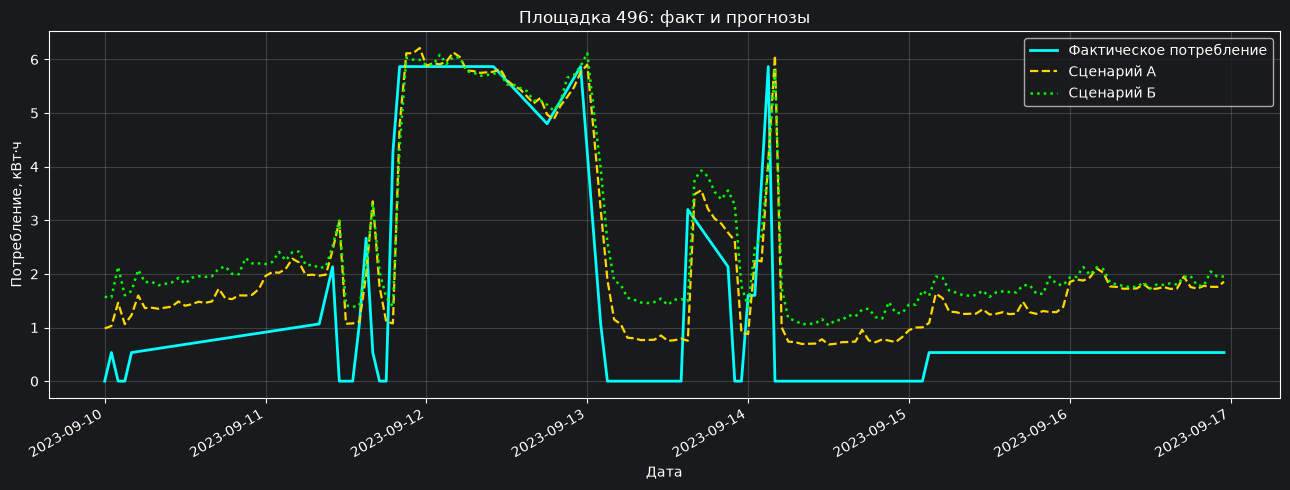

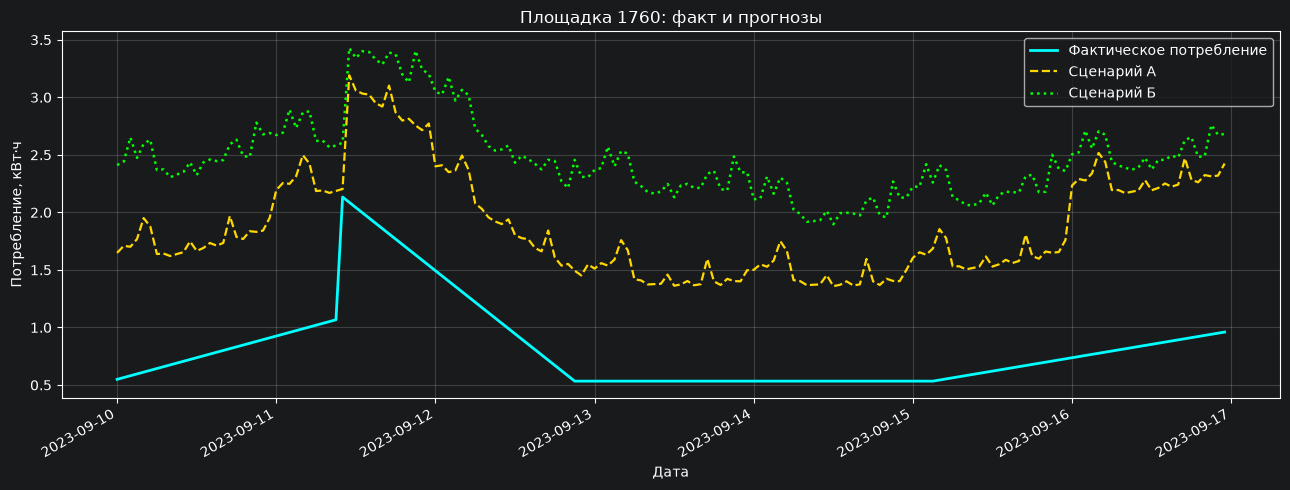

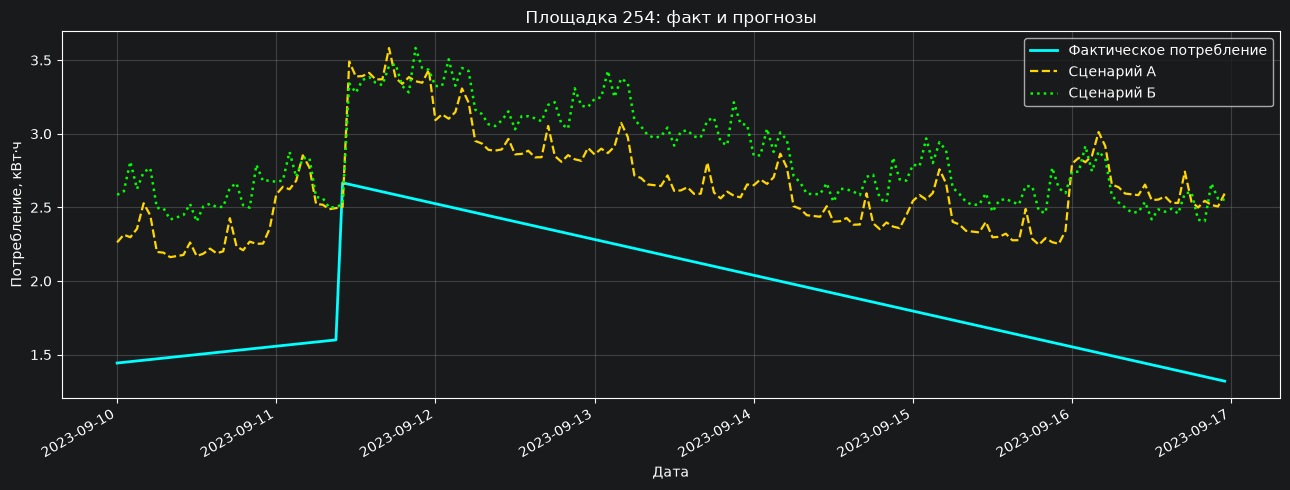

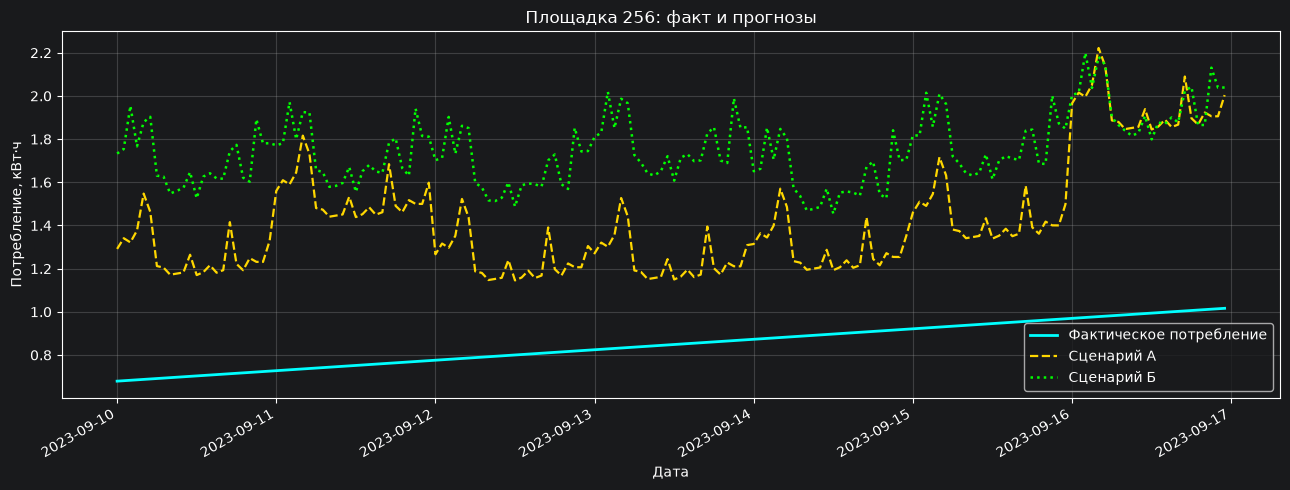

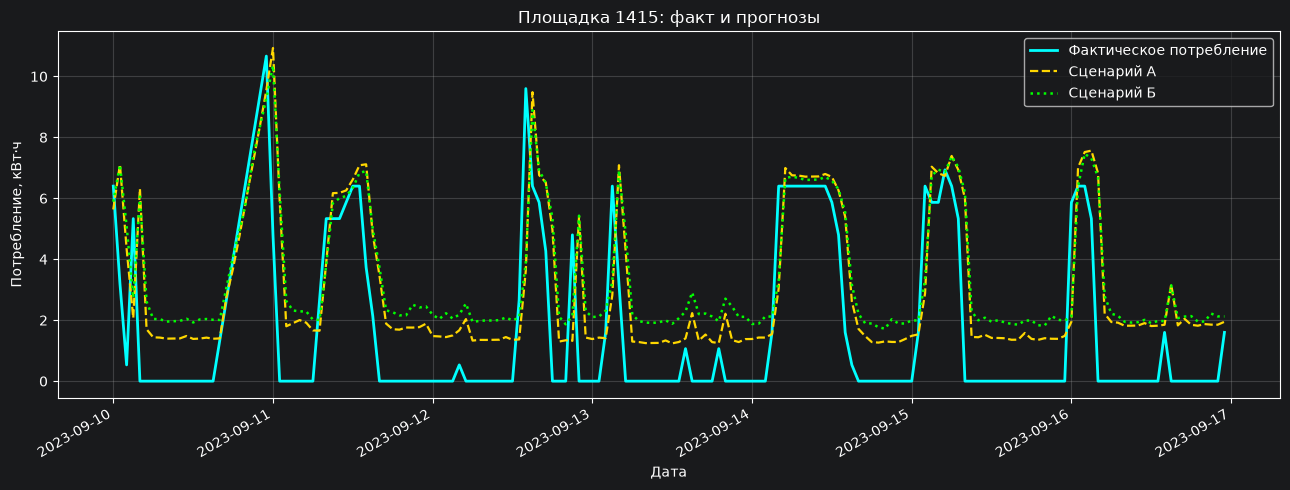


Оптимизация, сценарий A

Оптимизация, сценарий B

Максимальное отличие распределений LP и нашего метода:
0.0000000000 кВт

Итоги за август и сентябрь:
scenario    optimizer  predicted_max_deficit_pct  actual_max_deficit_pct  oracle_max_deficit_pct  allocated_reserve_kw  unused_reserve_kw  unmet_energy_kwh
       A Equalization                    17.7078                 23.3242                 11.1306                4.9763             1.0237            2.2791
       A           LP                    17.7078                 23.3242                 11.1306                4.9763             1.0237            2.2791
       B Equalization                    20.2405                 23.4418                 11.1306                5.3483             0.6517            2.3117
       B           LP                    20.2405                 23.4418                 11.1306                5.3483             0.6517            2.3117

Показатели по месяцам:
  month scenario    optimizer  predicted_max

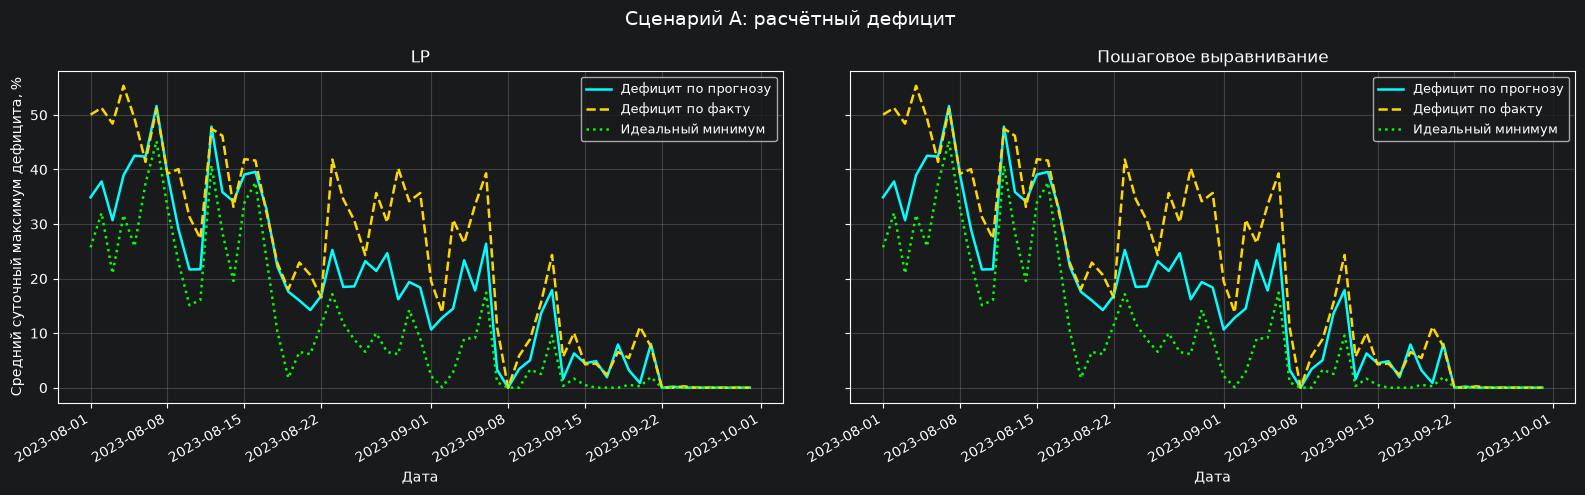

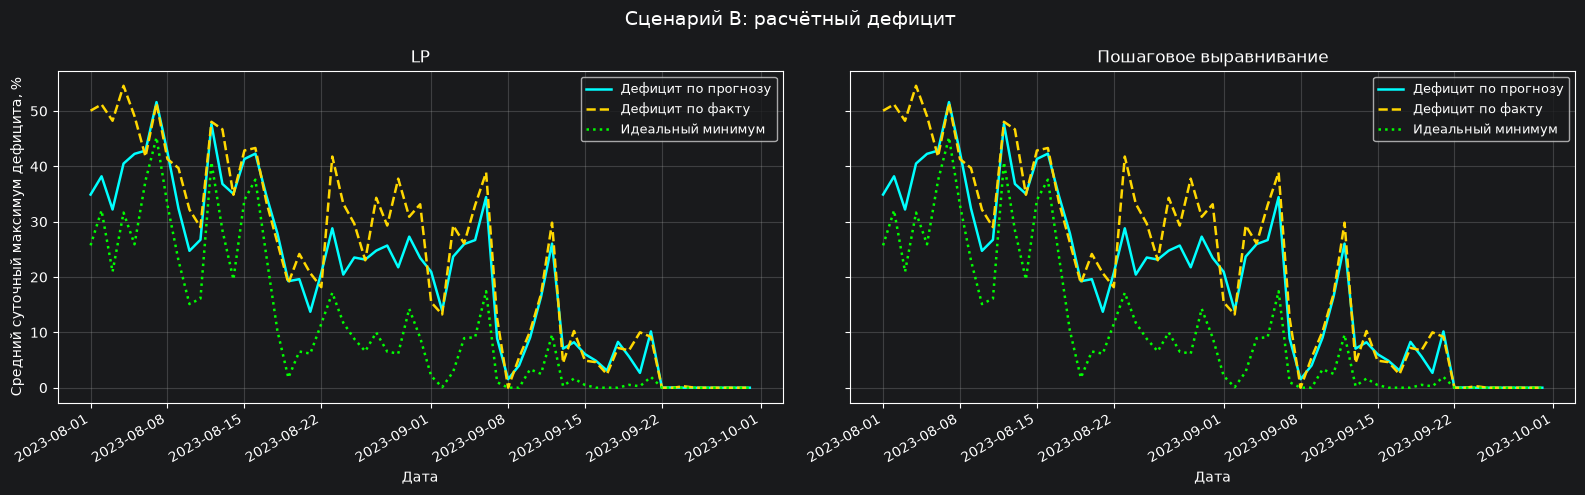


Время выполнения оптимизаторов:
Сценарий  Оптимизатор  Среднее, мс  Медиана, мс  Суммарное время, мс  Число запусков
       A Equalization       0.0268       0.0263              39.2608            1464
       A           LP       0.4296       0.4228             628.9405            1464
       B Equalization       0.0279       0.0283              40.8304            1464
       B           LP       0.4078       0.3990             597.0477            1464

Среднее время одного распределения:
Equalization: 0.0274 мс
LP: 0.4187 мс

Все расчёты завершены.
Папка результатов: /Users/lev/PycharmProjects/PAS_chargers/quantile_regression_q90_results
Папка графиков: /Users/lev/PycharmProjects/PAS_chargers/quantile_regression_q90_results/figures


In [1]:

from time import perf_counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import QuantileRegressor
from sklearn.metrics import mean_absolute_error, mean_pinball_loss
from scipy.optimize import linprog


# Настройки

FILENAME = "charged_ams_5_sites_2023-06-01_2023-09-30.csv"

SITES = ["496", "1760", "254", "256", "1415"]

BASE_POWER = np.array([1.0, 2.0, 1.0, 1.0, 1.0])
RESERVE_POWER = 6.0
INTERVAL_HOURS = 1.0

# Уровень квантиля. Регуляризацию выключаем, чтобы не подбирать новый параметр.
QUANTILE = 0.9
REGULARIZATION_ALPHA = 0.0

FEATURES = [
    "site_id",
    "lag_1",
    "lag_2",
    "lag_24",
    "hour",
    "day_of_week"
]

CATEGORICAL = ["site_id", "hour", "day_of_week"]
NUMERICAL = ["lag_1", "lag_2", "lag_24"]

COLORS = {
    "actual": "cyan",
    "A": "gold",
    "B": "lime",
    "predicted_deficit": "cyan",
    "actual_deficit": "gold",
    "oracle": "lime"
}

PLOT_START = "2023-09-10"
PLOT_END = "2023-09-17"

BASE_DIR = (
    Path(__file__).resolve().parent
    if "__file__" in globals()
    else Path.cwd()
)

search_paths = [
    BASE_DIR / FILENAME,
    BASE_DIR.parent / FILENAME
]

CSV_PATH = next(
    (path for path in search_paths if path.is_file()),
    None
)

if CSV_PATH is None:
    raise FileNotFoundError(
        "CSV не найден.\n"
        + "\n".join(str(path) for path in search_paths)
    )

OUTPUT_DIR = BASE_DIR / "quantile_regression_q90_results"
FIGURES_DIR = OUTPUT_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.facecolor": "#191a1c",
    "axes.facecolor": "#191a1c",
    "savefig.facecolor": "auto",
    "text.color": "white",
    "axes.labelcolor": "white",
    "xtick.color": "white",
    "ytick.color": "white",
    "axes.edgecolor": "white"
})


# Загрузка и проверка данных

df = pd.read_csv(str(CSV_PATH))

df["time"] = pd.to_datetime(df["time"])
df = df.sort_values("time").reset_index(drop=True)

for site in SITES:
    df[site] = pd.to_numeric(df[site], errors="raise")

expected_time = pd.date_range(
    "2023-06-01 00:00",
    "2023-09-30 23:00",
    freq="h"
)

assert pd.DatetimeIndex(df["time"]).equals(expected_time), (
    "Временной ряд неполный или содержит неверные даты"
)

assert df[SITES].notna().all().all(), (
    "Обнаружены пропущенные значения"
)

assert (df[SITES] >= 0).all().all(), (
    "Обнаружены отрицательные значения потребления"
)

print(f"Модель: линейная квантильная регрессия (квантиль {QUANTILE})")
print("Исходные данные:")
print("Часов:", len(df))
print("Площадок:", len(SITES))
print("Базовая мощность:", BASE_POWER.sum(), "кВт")
print("Резерв:", RESERVE_POWER, "кВт")


# Формирование признаков

data = df.melt(
    id_vars="time",
    value_vars=SITES,
    var_name="site_id",
    value_name="actual_kwh"
)

data = data.sort_values(
    ["site_id", "time"]
).reset_index(drop=True)

for lag in [1, 2, 24]:
    data[f"lag_{lag}"] = (
        data.groupby("site_id")["actual_kwh"].shift(lag)
    )

data["site_id"] = data["site_id"].astype(str)

data["hour"] = data["time"].dt.hour.astype(str)

data["day_of_week"] = (
    data["time"].dt.day_of_week.astype(str)
)

data = data.dropna(subset=FEATURES).copy()

june = data.loc[
    (data["time"] >= "2023-06-02")
    & (data["time"] < "2023-07-01")
].copy()

july = data.loc[
    (data["time"] >= "2023-07-01")
    & (data["time"] < "2023-08-01")
].copy()

train_full = data.loc[
    (data["time"] >= "2023-06-02")
    & (data["time"] < "2023-08-01")
].copy()

test = data.loc[
    (data["time"] >= "2023-08-01")
    & (data["time"] < "2023-10-01")
].copy()


# Линейная квантильная регрессия (q = 0,9)

def make_model():
    preprocessing = ColumnTransformer(
        transformers=[
            (
                "categories",
                OneHotEncoder(handle_unknown="ignore"),
                CATEGORICAL
            ),
            (
                "numbers",
                "passthrough",
                NUMERICAL
            )
        ]
    )

    quantile_model = QuantileRegressor(
        quantile=QUANTILE,
        alpha=REGULARIZATION_ALPHA,
        solver="highs"
    )

    return Pipeline([
        ("preprocessing", preprocessing),
        ("regression", quantile_model)
    ])

def predict_consumption(model, frame):
    prediction = model.predict(frame[FEATURES])
    return np.maximum(prediction, 0.0)


def calculate_mae(frame, column):
    return mean_absolute_error(
        frame["actual_kwh"],
        frame[column]
    )


# Первоначальное обучение на июне

model_june = make_model()

model_june.fit(
    june[FEATURES],
    june["actual_kwh"]
)

june_prediction = predict_consumption(
    model_june, june
)

july_prediction = predict_consumption(
    model_june, july
)

june_mae = mean_absolute_error(
    june["actual_kwh"],
    june_prediction
)

july_mae = mean_absolute_error(
    july["actual_kwh"],
    july_prediction
)

print("\nПервоначальная проверка:")
print(f"Июнь MAE: {june_mae:.4f}")
print(f"Июль MAE: {july_mae:.4f}")
print(
    f"Июнь Pinball Loss (q={QUANTILE}): "
    f"{mean_pinball_loss(june['actual_kwh'], june_prediction, alpha=QUANTILE):.4f}"
)
print(
    f"Июль Pinball Loss (q={QUANTILE}): "
    f"{mean_pinball_loss(july['actual_kwh'], july_prediction, alpha=QUANTILE):.4f}"
)


# Кривая обучения

train_days = [7, 14, 21, 29]

learning_rows = []

for days in train_days:
    cutoff = (
        pd.Timestamp("2023-06-02")
        + pd.Timedelta(days=days)
    )

    subset = june.loc[june["time"] < cutoff]

    model = make_model()

    model.fit(
        subset[FEATURES],
        subset["actual_kwh"]
    )

    train_prediction = predict_consumption(
        model, subset
    )

    validation_prediction = predict_consumption(
        model, july
    )

    learning_rows.append({
        "train_days": days,
        "train_mae": mean_absolute_error(
            subset["actual_kwh"],
            train_prediction
        ),
        "validation_mae": mean_absolute_error(
            july["actual_kwh"],
            validation_prediction
        )
    })

learning_df = pd.DataFrame(learning_rows)

print("\nКривая обучения:")
print(learning_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    learning_df["train_days"],
    learning_df["train_mae"],
    marker="o",
    linewidth=2,
    color=COLORS["actual"],
    label="Обучение (июнь)"
)

ax.plot(
    learning_df["train_days"],
    learning_df["validation_mae"],
    marker="s",
    linewidth=2,
    color=COLORS["A"],
    label="Проверка (июль)"
)

ax.set_title("Квантильная регрессия (0,9): кривая обучения")
ax.set_xlabel("Количество дней обучения")
ax.set_ylabel("MAE, кВт·ч")
ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "01_learning_curve.png",
    dpi=200
)

plt.show()


# Сценарий А

model_a = make_model()

model_a.fit(
    train_full[FEATURES],
    train_full["actual_kwh"]
)

test["pred_A"] = predict_consumption(
    model_a, test
)


# Сценарий Б

model_b = model_a

predictions_b = pd.Series(
    index=test.index,
    dtype=float
)

test_days = pd.date_range(
    "2023-08-01",
    "2023-09-30",
    freq="D"
)

for day_number, day in enumerate(test_days):
    next_day = day + pd.Timedelta(days=1)

    if day_number > 0:
        history = data.loc[
            (data["time"] >= "2023-06-02")
            & (data["time"] < day)
        ]

        model_b = make_model()

        model_b.fit(
            history[FEATURES],
            history["actual_kwh"]
        )

    day_data = test.loc[
        (test["time"] >= day)
        & (test["time"] < next_day)
    ]

    predictions_b.loc[day_data.index] = (
        predict_consumption(model_b, day_data)
    )

test["pred_B"] = predictions_b

assert test[["pred_A", "pred_B"]].notna().all().all()

for scenario in ["A", "B"]:
    test[f"error_{scenario}"] = (
        test["actual_kwh"]
        - test[f"pred_{scenario}"]
    ).abs()

print("\nКачество прогнозов за август и сентябрь:")

for scenario in ["A", "B"]:
    print(
        f"Сценарий {scenario}: "
        f"MAE = {calculate_mae(test, f'pred_{scenario}'):.4f} кВт·ч; "
        f"Pinball Loss = {mean_pinball_loss(test['actual_kwh'], test[f'pred_{scenario}'], alpha=QUANTILE):.4f}"
    )

print("\nКачество прогнозов по месяцам:")
for month, subset in test.groupby(test["time"].dt.strftime("%Y-%m")):
    for scenario in ["A", "B"]:
        print(
            f"{month}, сценарий {scenario}: "
            f"MAE = {calculate_mae(subset, f'pred_{scenario}'):.4f} кВт·ч; "
            f"Pinball Loss = {mean_pinball_loss(subset['actual_kwh'], subset[f'pred_{scenario}'], alpha=QUANTILE):.4f}"
        )


# Динамика суточной MAE

daily_mae = (
    test.set_index("time")
    .groupby(pd.Grouper(freq="D"))[
        ["error_A", "error_B"]
    ]
    .mean()
)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    daily_mae.index,
    daily_mae["error_A"],
    linewidth=1.8,
    color=COLORS["A"],
    label="Сценарий А"
)

ax.plot(
    daily_mae.index,
    daily_mae["error_B"],
    linewidth=1.8,
    linestyle="--",
    color=COLORS["B"],
    label="Сценарий Б"
)

ax.set_title("Динамика суточной MAE")
ax.set_xlabel("Дата")
ax.set_ylabel("MAE, кВт·ч")
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "02_daily_mae.png",
    dpi=200
)

plt.show()


# Графики прогнозов для каждой площадки

plot_data = test.loc[
    (test["time"] >= PLOT_START)
    & (test["time"] < PLOT_END)
]

for site in SITES:
    subset = plot_data.loc[
        plot_data["site_id"] == site
    ].sort_values("time")

    fig, ax = plt.subplots(figsize=(13, 5))

    ax.plot(
        subset["time"],
        subset["actual_kwh"],
        color=COLORS["actual"],
        linewidth=2,
        label="Фактическое потребление"
    )

    ax.plot(
        subset["time"],
        subset["pred_A"],
        color=COLORS["A"],
        linestyle="--",
        linewidth=1.6,
        label="Сценарий А"
    )

    ax.plot(
        subset["time"],
        subset["pred_B"],
        color=COLORS["B"],
        linestyle=":",
        linewidth=1.8,
        label="Сценарий Б"
    )

    ax.set_title(f"Площадка {site}: факт и прогнозы")
    ax.set_xlabel("Дата")
    ax.set_ylabel("Потребление, кВт·ч")
    ax.legend()

    fig.autofmt_xdate()
    fig.tight_layout()

    fig.savefig(
        FIGURES_DIR / f"forecast_site_{site}.png",
        dpi=200
    )

    plt.show()


# Относительный дефицит

def relative_deficits(demand_kw, allocated_kw):
    demand = np.asarray(demand_kw, dtype=float)
    allocated = np.asarray(allocated_kw, dtype=float)

    shortage = np.maximum(
        demand - allocated, 0.0
    )

    return np.divide(
        shortage,
        demand,
        out=np.zeros_like(demand),
        where=demand > 0
    )


def max_relative_deficit(demand_kw, reserve_kw):
    available = BASE_POWER + reserve_kw

    deficits = relative_deficits(
        demand_kw,
        available
    )

    return float(np.max(deficits))


# LP: минимум максимального относительного дефицита

def optimize_lp(predicted_kw):
    predicted = np.maximum(
        np.asarray(predicted_kw, dtype=float),
        0.0
    )

    n = len(predicted)

    c = np.zeros(n + 1)
    c[-1] = 1.0

    A_ub = np.zeros((n + 1, n + 1))
    b_ub = np.zeros(n + 1)

    for i in range(n):
        A_ub[i, i] = -1.0
        A_ub[i, -1] = -predicted[i]

        b_ub[i] = BASE_POWER[i] - predicted[i]

    A_ub[-1, :n] = 1.0
    b_ub[-1] = RESERVE_POWER

    bounds = (
        [(0, None)] * n
        + [(0, 1)]
    )

    result = linprog(
        c,
        A_ub=A_ub,
        b_ub=b_ub,
        bounds=bounds,
        method="highs"
    )

    if not result.success:
        raise RuntimeError(result.message)

    optimal_deficit = float(
        np.clip(result.x[-1], 0.0, 1.0)
    )

    # Минимальный резерв для найденного уровня дефицита
    reserve = np.maximum(
        (1.0 - optimal_deficit) * predicted
        - BASE_POWER,
        0.0
    )

    # Коррекция численной погрешности
    if reserve.sum() > RESERVE_POWER:
        reserve *= RESERVE_POWER / reserve.sum()

    return reserve


# Пошаговое выравнивание относительного дефицита

def optimize_equalization(predicted_kw):
    predicted = np.maximum(
        np.asarray(predicted_kw, dtype=float),
        0.0
    )

    initial_deficits = relative_deficits(
        predicted,
        BASE_POWER
    )

    positive_levels = np.unique(
        initial_deficits[initial_deficits > 1e-12]
    )[::-1]

    reserve = np.zeros_like(predicted)
    remaining = RESERVE_POWER

    if len(positive_levels) == 0:
        return reserve

    for index, current_level in enumerate(positive_levels):
        active = (
            initial_deficits >= current_level - 1e-12
        )

        if index + 1 < len(positive_levels):
            next_level = positive_levels[index + 1]
        else:
            next_level = 0.0

        drop = current_level - next_level

        required = (
            predicted[active].sum() * drop
        )

        if required <= remaining + 1e-10:
            reserve[active] += (
                predicted[active] * drop
            )

            remaining = max(
                0.0,
                remaining - required
            )

        else:
            weight = predicted[active].sum()

            reduction = remaining / weight

            reserve[active] += (
                predicted[active] * reduction
            )

            remaining = 0.0
            break

    return reserve


# Подготовка почасовых данных для оптимизаторов

actual_wide = (
    test.pivot(
        index="time",
        columns="site_id",
        values="actual_kwh"
    )
    .reindex(columns=SITES)
    .sort_index()
)

predictions_wide = {}

for scenario in ["A", "B"]:
    predictions_wide[scenario] = (
        test.pivot(
            index="time",
            columns="site_id",
            values=f"pred_{scenario}"
        )
        .reindex(columns=SITES)
        .sort_index()
    )

assert actual_wide.notna().all().all()

for scenario in ["A", "B"]:
    assert predictions_wide[scenario].notna().all().all()


# Идеальный минимум при заранее известном факте

oracle_deficits = {}

for time, row in actual_wide.iterrows():
    actual_kw = (
        row.to_numpy(dtype=float) / INTERVAL_HOURS
    )

    ideal_reserve = optimize_equalization(actual_kw)

    oracle_deficits[time] = max_relative_deficit(
        actual_kw,
        ideal_reserve
    )


# Четыре сочетания сценариев и оптимизаторов

optimizers = {
    "LP": optimize_lp,
    "Equalization": optimize_equalization
}

records = []

maximum_allocation_difference = 0.0

for scenario in ["A", "B"]:
    print(f"\nОптимизация, сценарий {scenario}")

    for time in actual_wide.index:
        actual_kwh = actual_wide.loc[
            time
        ].to_numpy(dtype=float)

        predicted_kwh = predictions_wide[
            scenario
        ].loc[time].to_numpy(dtype=float)

        predicted_kw = (
            predicted_kwh / INTERVAL_HOURS
        )

        actual_kw = (
            actual_kwh / INTERVAL_HOURS
        )

        allocations = {}

        for optimizer_name, optimizer_function in (
            optimizers.items()
        ):
            start_time = perf_counter()

            reserve = optimizer_function(predicted_kw)

            elapsed_ms = (
                perf_counter() - start_time
            ) * 1000

            allocations[optimizer_name] = reserve

            if reserve.sum() > RESERVE_POWER + 1e-7:
                raise ValueError(
                    "Превышен доступный резерв"
                )

            predicted_deficit = max_relative_deficit(
                predicted_kw,
                reserve
            )

            actual_deficit = max_relative_deficit(
                actual_kw,
                reserve
            )

            actual_shortage_kw = np.maximum(
                actual_kw - BASE_POWER - reserve,
                0.0
            )

            row = {
                "time": time,
                "optimization_time_ms": elapsed_ms,
                "scenario": scenario,
                "optimizer": optimizer_name,
                "predicted_max_deficit_pct":
                    predicted_deficit * 100,
                "actual_max_deficit_pct":
                    actual_deficit * 100,
                "oracle_max_deficit_pct":
                    oracle_deficits[time] * 100,
                "allocated_reserve_kw":
                    float(reserve.sum()),
                "unused_reserve_kw":
                    float(
                        max(
                            0.0,
                            RESERVE_POWER - reserve.sum()
                        )
                    ),
                "unmet_energy_kwh":
                    float(
                        actual_shortage_kw.sum()
                        * INTERVAL_HOURS
                    )
            }

            for index, site in enumerate(SITES):
                row[f"reserve_{site}_kw"] = reserve[index]

                row[f"forecast_{site}_kwh"] = (
                    predicted_kwh[index]
                )

                row[f"actual_{site}_kwh"] = (
                    actual_kwh[index]
                )

            records.append(row)

        difference = np.max(
            np.abs(
                allocations["LP"]
                - allocations["Equalization"]
            )
        )

        maximum_allocation_difference = max(
            maximum_allocation_difference,
            float(difference)
        )

results = pd.DataFrame(records)

print("\nМаксимальное отличие распределений LP и нашего метода:")
print(f"{maximum_allocation_difference:.10f} кВт")

assert maximum_allocation_difference < 1e-6, (
    "Оптимизаторы дали разные распределения"
)


# Итоговые показатели

quality_columns = [
    "predicted_max_deficit_pct",
    "actual_max_deficit_pct",
    "oracle_max_deficit_pct",
    "allocated_reserve_kw",
    "unused_reserve_kw",
    "unmet_energy_kwh"
]

summary = (
    results.groupby(
        ["scenario", "optimizer"]
    )[quality_columns]
    .mean()
    .reset_index()
)

print("\nИтоги за август и сентябрь:")
print(summary.round(4).to_string(index=False))


# Средний максимальный дефицит по месяцам

results["month"] = (
    pd.to_datetime(results["time"])
    .dt.strftime("%Y-%m")
)

monthly = (
    results.groupby(
        ["month", "scenario", "optimizer"]
    )[
        [
            "predicted_max_deficit_pct",
            "actual_max_deficit_pct",
            "oracle_max_deficit_pct",
            "allocated_reserve_kw",
            "unused_reserve_kw"
        ]
    ]
    .mean()
    .reset_index()
)

print("\nПоказатели по месяцам:")
print(monthly.round(4).to_string(index=False))


# Графики дефицита для сценариев А и Б

for scenario in ["A", "B"]:
    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(16, 5),
        sharey=True
    )

    for ax, optimizer_name in zip(
        axes,
        optimizers.keys()
    ):
        subset = results.loc[
            (results["scenario"] == scenario)
            & (results["optimizer"] == optimizer_name)
        ].copy()

        daily = (
            subset.set_index("time")
            .resample("D")[
                [
                    "predicted_max_deficit_pct",
                    "actual_max_deficit_pct",
                    "oracle_max_deficit_pct"
                ]
            ]
            .mean()
        )

        ax.plot(
            daily.index,
            daily["predicted_max_deficit_pct"],
            color=COLORS["predicted_deficit"],
            linewidth=1.8,
            label="Дефицит по прогнозу"
        )

        ax.plot(
            daily.index,
            daily["actual_max_deficit_pct"],
            color=COLORS["actual_deficit"],
            linestyle="--",
            linewidth=1.8,
            label="Дефицит по факту"
        )

        ax.plot(
            daily.index,
            daily["oracle_max_deficit_pct"],
            color=COLORS["oracle"],
            linestyle=":",
            linewidth=1.8,
            label="Идеальный минимум"
        )

        name = (
            "LP"
            if optimizer_name == "LP"
            else "Пошаговое выравнивание"
        )

        ax.set_title(name)
        ax.set_xlabel("Дата")
        ax.legend(fontsize=9)

    axes[0].set_ylabel(
        "Средний суточный максимум дефицита, %"
    )

    fig.suptitle(
        f"Сценарий {scenario}: расчётный дефицит",
        fontsize=14
    )

    fig.autofmt_xdate()
    fig.tight_layout()

    fig.savefig(
        FIGURES_DIR / f"deficits_scenario_{scenario}.png",
        dpi=200
    )

    plt.show()


# Сохранение таблиц

learning_df.to_csv(
    OUTPUT_DIR / "learning_curve.csv",
    index=False,
    encoding="utf-8-sig"
)

daily_mae.to_csv(
    OUTPUT_DIR / "daily_mae.csv",
    encoding="utf-8-sig"
)

test[
    [
        "time",
        "site_id",
        "actual_kwh",
        "pred_A",
        "pred_B",
        "error_A",
        "error_B"
    ]
].sort_values(
    ["time", "site_id"]
).to_csv(
    OUTPUT_DIR / "predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

results.to_csv(
    OUTPUT_DIR / "hourly_recommendations.csv",
    index=False,
    encoding="utf-8-sig"
)

summary.to_csv(
    OUTPUT_DIR / "summary.csv",
    index=False,
    encoding="utf-8-sig"
)

monthly.to_csv(
    OUTPUT_DIR / "monthly_summary.csv",
    index=False,
    encoding="utf-8-sig"
)


# Среднее время выполнения оптимизаторов

timing_summary = (
    results.groupby(["scenario", "optimizer"])
    ["optimization_time_ms"]
    .agg(["mean", "median", "sum", "count"])
    .reset_index()
)

timing_summary.columns = [
    "Сценарий",
    "Оптимизатор",
    "Среднее, мс",
    "Медиана, мс",
    "Суммарное время, мс",
    "Число запусков"
]

print("\nВремя выполнения оптимизаторов:")
print(timing_summary.round(4).to_string(index=False))

overall_timing = (
    results.groupby("optimizer")["optimization_time_ms"]
    .mean()
)

print("\nСреднее время одного распределения:")
for name, value in overall_timing.items():
    print(f"{name}: {value:.4f} мс")

timing_summary.to_csv(
    OUTPUT_DIR / "optimizer_timing.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nВсе расчёты завершены.")
print("Папка результатов:", OUTPUT_DIR)
print("Папка графиков:", FIGURES_DIR)
